# **_DATA CLEANING & PREPROCESSING_**

importing libraries and loading `DataFrame`

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
raw_data = pd.read_excel(r"c://users/danhaya/arewads/concrete_research/data/Concrete_Data.xls")
raw_data.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [13]:
for col in raw_data.columns:
    print(col)

Cement (component 1)(kg in a m^3 mixture)
Blast Furnace Slag (component 2)(kg in a m^3 mixture)
Fly Ash (component 3)(kg in a m^3 mixture)
Water  (component 4)(kg in a m^3 mixture)
Superplasticizer (component 5)(kg in a m^3 mixture)
Coarse Aggregate  (component 6)(kg in a m^3 mixture)
Fine Aggregate (component 7)(kg in a m^3 mixture)
Age (day)
Concrete compressive strength(MPa, megapascals) 


### Renaming column names for ease `Data manipulation` and `vizualizations`

In [4]:
raw_data.columns = ["cement", "BFS", "FA", "water", "SP", "C-Agg", "F-Agg", "age", "CS"]
print(raw_data.columns)

Index(['cement', 'BFS', 'FA', 'water', 'SP', 'C-Agg', 'F-Agg', 'age', 'CS'], dtype='object')


### check for missing values (null values)

In [5]:
print(raw_data.isna().sum())

cement    0
BFS       0
FA        0
water     0
SP        0
C-Agg     0
F-Agg     0
age       0
CS        0
dtype: int64


This `Dataset` contains no missing values 

### check for duplicate values

In [17]:
print(raw_data.duplicated().sum())

25


In [18]:
raw_data.shape

(1030, 9)

In [6]:
raw_data = raw_data.drop_duplicates()
raw_data.shape


(1005, 9)

25 duplicate values were identified and dropped.

### **Handling Outliers**

In [5]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1005 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cement                1005 non-null   float64
 1   blast_furnace_slag    1005 non-null   float64
 2   fly_ash               1005 non-null   float64
 3   water                 1005 non-null   float64
 4   superplasticizer      1005 non-null   float64
 5   coarse_aggregate      1005 non-null   float64
 6   fine_aggregate        1005 non-null   float64
 7   age                   1005 non-null   int64  
 8   compressive_strength  1005 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 78.5 KB


In [6]:
raw_data.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.629055,72.043134,55.535075,182.074378,6.031647,974.376468,772.686617,45.856716,35.250273
std,104.345003,86.170555,64.207448,21.340740,5.919559,77.579534,80.339851,63.734692,16.284808
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,190.680000,0.000000,0.000000,166.610000,0.000000,932.000000,724.300000,7.000000,23.523542
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.798114
75%,349.000000,142.500000,118.270000,192.940000,10.000000,1031.000000,822.200000,56.000000,44.868340
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


Information deduced from these tables have shown that there values that can be considered as outliers. let me identify the outliers and remove them using interquartile range `(iqr)`

In [7]:
from scipy.stats import iqr
import numpy as np

# Make a copy to keep original safe
df = raw_data.copy()


mask = np.ones(len(df), dtype=bool)
col_list = raw_data.columns

for col in col_list:
    data = df[col].values
    col_iqr = iqr(data)
    q1 = np.quantile(data, 0.25)
    q3 = np.quantile(data, 0.75)
    lower_threshold = q1 - 1.5 * col_iqr
    upper_threshold = q3 + 1.5 * col_iqr
    
    # Update mask
    mask &= (data >= lower_threshold) & (data <= upper_threshold)

# Apply mask once
clean_raw_data = df[mask]

print("Original shape:", raw_data.shape)
print("After removing outliers:", clean_raw_data.shape)


Original shape: (1005, 9)
After removing outliers: (911, 9)


This shows that 94 enteries have been identified as outliers and removed.

### **Distribution of the Data**

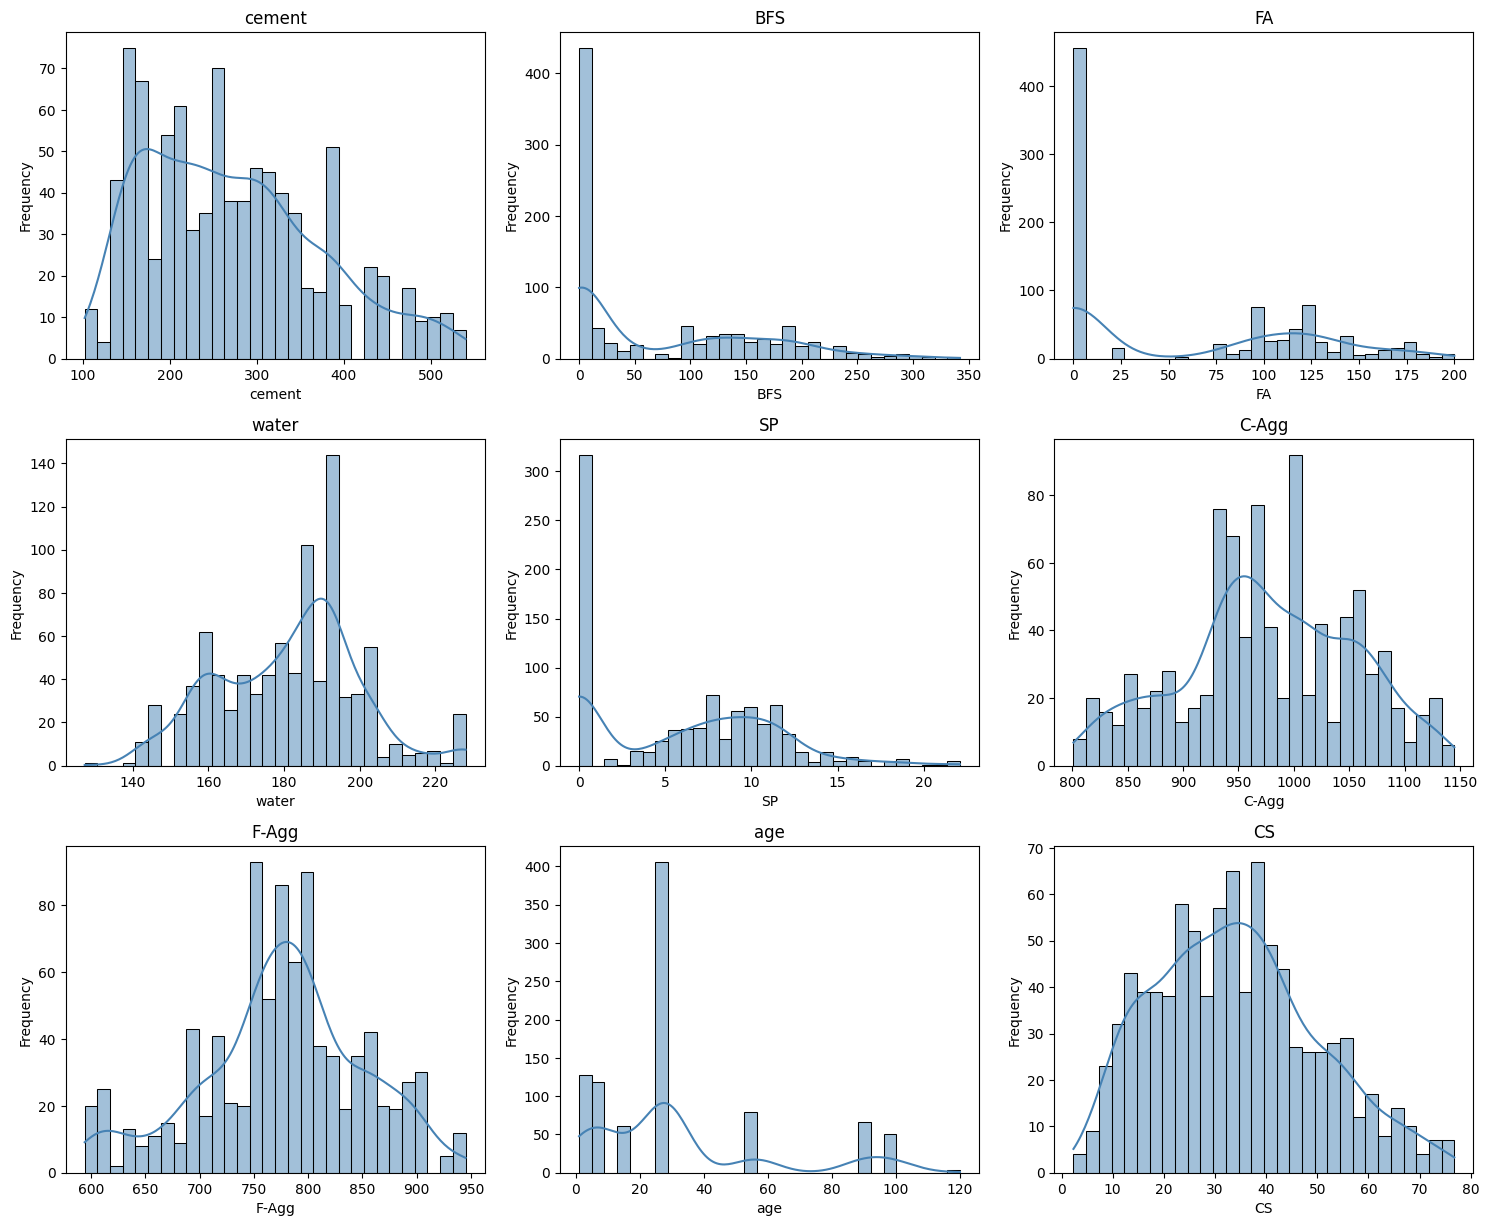

In [8]:
import seaborn as sns

columns = clean_raw_data.columns

# Number of features
n = len(columns)
rows = (n // 3) + 1
cols =3

plt.figure(figsize=(15, 4*rows))

for i, col in enumerate(columns, 1):
    if col == 'water_cement_ratio':
        break
    
    plt.subplot(rows, cols, i)
    sns.histplot(clean_raw_data[col], kde=True, bins=30, color='steelblue')
    plt.title(f'{col}')
    plt.xlabel(col)
    plt.ylabel("Frequency")
    

plt.tight_layout()
plt.show()

This plot shows that the distribution of the data can be approxiated to normal which is suitable for training machine learning models.

### **Engineering-Based Feature Design**

In this section, four engineering features were introduced to the dataset namely:
- water-cement ratio
- Binder content
- water-binder ratio
- Aggregate ratio

$$
water-cement-ratio (w/c)= water/cement 
$$
$$
binder = cement + slag + flyash
$$
$$
water-binder-ratio (w/b) = water/binder
$$
$$
aggregate-ratio = fine aggregate/coarse aggregate
$$

In [1]:
import pandas as pd

eng_data = pd.read_csv("../data/eng_data.csv")

eng_data.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength,w_c,binder,w_b,agg_ratio
0,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366,0.300000,540.0,0.30,0.640758
1,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.029847,0.857143,380.0,0.60,0.718884
2,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.447770,0.600000,475.0,0.48,0.637339
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.854291,0.857143,380.0,0.60,0.718884
4,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.289790,0.480000,475.0,0.48,0.637339


In [4]:
#copy the raw data and introduce the engineering features
eng_data['w/c'] = eng_data['water'] / eng_data['cement']
eng_data['binder'] = eng_data['cement'] + eng_data['blast_furnace_slag'] + eng_data['fly_ash']
eng_data['w/b'] = eng_data['water'] / eng_data['binder']
eng_data['agg_ratio'] = eng_data['fine_aggregate'] / eng_data['coarse_aggregate']

eng_fea = eng_data[["w/c", "binder", "w/b", "agg_ratio"]]

eng_fea.head()



,w/c,binder,w/b,agg_ratio
0,0.300000,540.0,0.30,0.640758
1,0.857143,380.0,0.60,0.718884
2,0.600000,475.0,0.48,0.637339
3,0.857143,380.0,0.60,0.718884
4,0.480000,475.0,0.48,0.637339


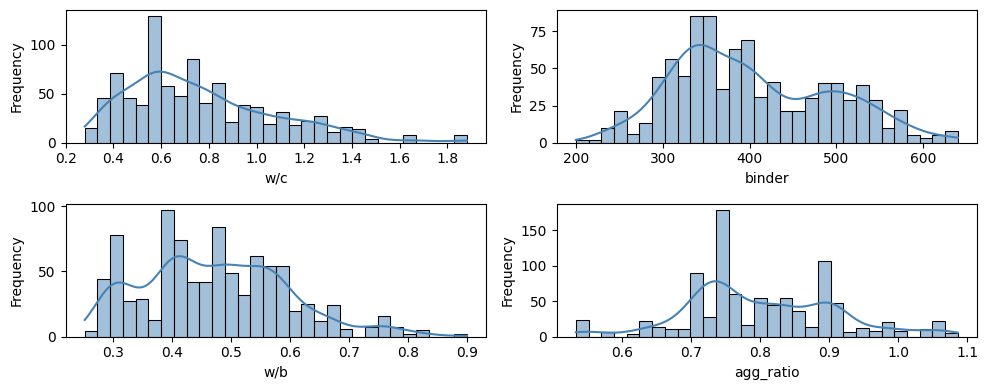

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

columns = eng_fea.columns

# Number of features
n = len(columns)
rows = (n // 4) + 1
cols = 2

plt.figure(figsize=(10, 2*rows))

for i, col in enumerate(columns, 1):
    #if col == 'water_cement_ratio':
        #break
    
    plt.subplot(rows, cols, i)
    sns.histplot(eng_fea[col], kde=True, bins=30, color='steelblue')
    #plt.title(f'{col}')
    plt.xlabel(col)
    plt.ylabel("Frequency")
    

plt.tight_layout()
plt.show()

### **Correlation Analysis**

in this section we're going to explore the correlation among the features with compressive strength



In [16]:
col_of_interest = ["w/c", "binder", "w/b", "agg_ratio", "compressive_strength"]
df_of_interest = eng_data[col_of_interest]
df_of_interest.columns = ["w/c", "binder", "w/b", "agg_ratio", "CS"]
print(df_of_interest.head())

        w/c  binder   w/b  agg_ratio         CS
0  0.300000   540.0  0.30   0.640758  61.887366
1  0.857143   380.0  0.60   0.718884  47.029847
2  0.600000   475.0  0.48   0.637339  36.447770
3  0.857143   380.0  0.60   0.718884  45.854291
4  0.480000   475.0  0.48   0.637339  39.289790


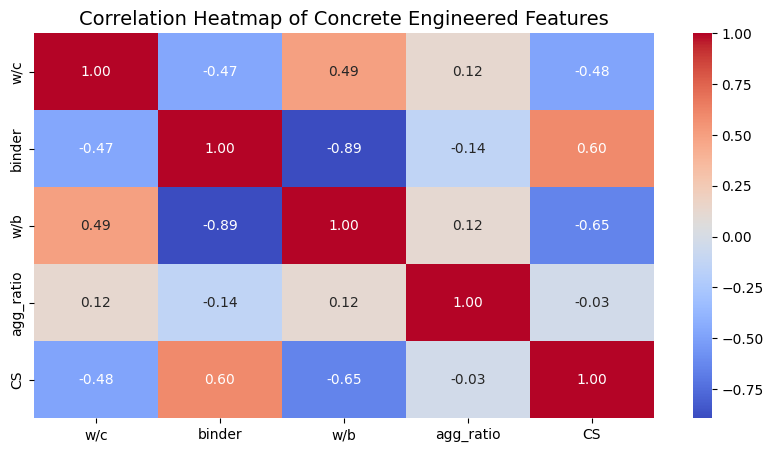

In [18]:
corr_matrix = df_of_interest.corr()

plt.figure(figsize=(10, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Heatmap of Concrete Engineered Features", fontsize=14)
plt.show()

In [16]:
eng_data.to_csv("../data/eng_data.csv", index=False)
clean_raw_data.to_csv("../data/raw_data.csv", index=False)

Both Raw data and Engineering are now ready for Machine learning modelling.